In [42]:
import os

import keras
import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf
import tensorflow_datasets as tfds
from keras import layers, models, regularizers
from keras.callbacks import EarlyStopping
from keras.optimizers import Adam
from sklearn.datasets import load_digits
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.model_selection import train_test_split

In [43]:
tf.config.threading.set_intra_op_parallelism_threads(4)
tf.config.threading.set_inter_op_parallelism_threads(1)

print("TensorFlow:", tf.__version__)
print("GPU для TensorFlow:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.21.0
GPU для TensorFlow: []


In [44]:
ds_train, ds_val, ds_test = tfds.load(
    "svhn_cropped",
    split=[
        "train[:90%]",
        "train[90%:]",
        "test"
    ],
    as_supervised=True
)

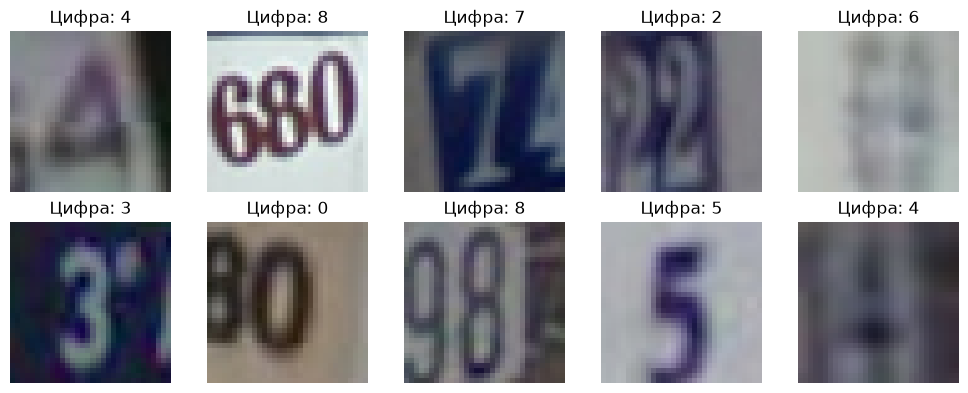

In [45]:
fig, axes = plt.subplots(2,5,figsize=(10,4))

for i, (image, label) in enumerate(ds_train.take(10)):
    axes.flat[i].imshow(image.numpy())
    axes.flat[i].set_title(f"Цифра: {int(label.numpy())}")
    axes.flat[i].axis("off")

plt.tight_layout()
plt.show()

In [46]:
train_ds = (
    ds_train
    .shuffle(10000, seed=42)
    .batch(64)
    .prefetch(1)
)

val_ds = (
    ds_val
    .batch(64)
    .prefetch(1)
)

test_ds = (
    ds_test
    .batch(64)
    .prefetch(1)
)

In [ ]:
model_cnn.compile(
    optimizer=Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["sparse_categorical_accuracy"]
)

In [49]:
early_stop = EarlyStopping(
    monitor='val_sparse_categorical_accuracy',
    patience=7,
    restore_best_weights=True
)

os.makedirs("checkpoints", exist_ok=True)
checkpoint_path = "checkpoints/svhn-cnn.keras"

checkpoint = tf.keras.callbacks.ModelCheckpoint(
    filepath=checkpoint_path,
    monitor="val_sparse_categorical_accuracy",
    mode="max",
    save_best_only=True,
    save_weights_only=False,
    verbose=1
)

if os.path.exists(checkpoint_path):
    cnn = tf.keras.models.load_model(checkpoint_path)
    print("Загружена сохранённая модель")

In [50]:
history_cnn = model_cnn.fit(
    train_ds,
    validation_data=val_ds,
    epochs=50,
    callbacks=[early_stop, checkpoint]
)

Epoch 1/50


/home/dd/dl-projects/.venv/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


1030/1031 ━━━━━━━━━━━━━━━━━━━━ 0s 79ms/step - loss: 1.8867 - sparse_categorical_accuracy: 0.3473
Epoch 1: val_sparse_categorical_accuracy improved from None to 0.42411, saving model to checkpoints/svhn-cnn.keras

Epoch 1: finished saving model to checkpoints/svhn-cnn.keras
1031/1031 ━━━━━━━━━━━━━━━━━━━━ 87s 81ms/step - loss: 1.8866 - sparse_categorical_accuracy: 0.3473 - val_loss: 1.5510 - val_sparse_categorical_accuracy: 0.4241
Epoch 2/50
1030/1031 ━━━━━━━━━━━━━━━━━━━━ 0s 84ms/step - loss: 1.3131 - sparse_categorical_accuracy: 0.5712
Epoch 2: val_sparse_categorical_accuracy improved from 0.42411 to 0.54477, saving model to checkpoints/svhn-cnn.keras

Epoch 2: finished saving model to checkpoints/svhn-cnn.keras
1031/1031 ━━━━━━━━━━━━━━━━━━━━ 89s 86ms/step - loss: 1.3130 - sparse_categorical_accuracy: 0.5712 - val_loss: 1.3631 - val_sparse_categorical_accuracy: 0.5448
Epoch 3/50
1030/1031 ━━━━━━━━━━━━━━━━━━━━ 0s 84ms/step - loss: 1.0419 - sparse_categorical_accuracy: 0.6667
Epoch 3: val

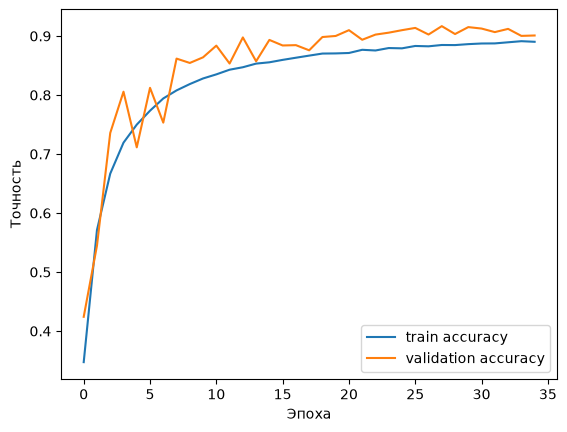

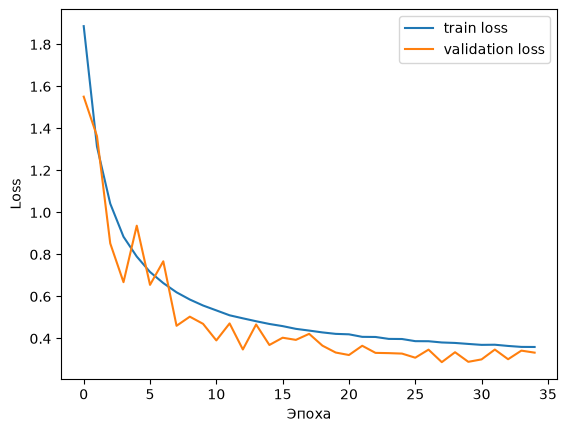

In [51]:
plt.plot(history_cnn.history['sparse_categorical_accuracy'], label='train accuracy')
plt.plot(history_cnn.history['val_sparse_categorical_accuracy'], label='validation accuracy')
plt.xlabel('Эпоха')
plt.ylabel('Точность')
plt.legend()
plt.show()

plt.plot(history_cnn.history['loss'], label='train loss')
plt.plot(history_cnn.history['val_loss'], label='validation loss')
plt.xlabel('Эпоха')
plt.ylabel('Loss')
plt.legend()
plt.show()

In [52]:
test_loss, test_accuracy = model_cnn.evaluate(test_ds)
print(f"Test accuracy: {test_accuracy:.2%}")

407/407 ━━━━━━━━━━━━━━━━━━━━ 6s 14ms/step - loss: 0.2416 - sparse_categorical_accuracy: 0.9367
Test accuracy: 93.67%


In [53]:
probs = model_cnn.predict(test_ds, verbose=1)

y_pred = np.argmax(probs, axis=1)

y_true = np.concatenate([
    labels.numpy()
    for images, labels in test_ds
])

407/407 ━━━━━━━━━━━━━━━━━━━━ 6s 14ms/step


In [54]:
print(confusion_matrix(y_true, y_pred))
print(classification_report(y_true, y_pred))

[[1690   23    6    1    1    3    6    2    8    4]
 [  54 4944   21    9   21    6    9   29    2    4]
 [  13   65 3991   33   11    2    2   18    6    8]
 [  20   87   41 2596   12   34    6    7   35   44]
 [   9   75   16    3 2406    2    1    5    3    3]
 [  15   27    8   54   11 2214   35    4   11    5]
 [  43   32   11   13    4   20 1831    4   18    1]
 [   7  126   35   10    7    4    2 1825    2    1]
 [  39   30   17   16    8   13   51    0 1458   28]
 [  53   30   47    6    5    6    5    3   10 1430]]
              precision    recall  f1-score   support

           0       0.87      0.97      0.92      1744
           1       0.91      0.97      0.94      5099
           2       0.95      0.96      0.96      4149
           3       0.95      0.90      0.92      2882
           4       0.97      0.95      0.96      2523
           5       0.96      0.93      0.94      2384
           6       0.94      0.93      0.93      1977
           7       0.96      0.90   